# Kalman-Filtered Pairs Trading with Rolling Coherence Gating

This research notebook compares two rules-based pairs-trading systems across a predeclared universe of equity pairs:

1. **Normal Kalman:** a causal Kalman filter estimates a time-varying hedge ratio, with no coherence gate.
2. **Coherence-gated Kalman:** the same core framework restricts model updates during low-coherence periods and uses the configured trade-level beta and z-score rules.

The coherence proxy is **squared rolling Pearson correlation of asset returns**. It is not wavelet coherence. The notebook selects parameters on development data, evaluates the selected configurations on a separate date range, and produces pair-level, aggregate, uncertainty, and diagnostic outputs.

## Quick start

1. Install the dependencies listed in the README.
2. Review `CONFIG` before running anything, especially the pair universe, dates, stop/lookback grids, costs, and `TEST_ALREADY_INSPECTED`.
3. Run the notebook from top to bottom. By default, market data are downloaded with `yfinance` and cached locally; existing cache files are used on later runs.
4. Inspect training eligibility and selected parameters before interpreting evaluation period comparisons. Generated CSVs, JSON manifests, and plots are written to `final_multiple_pair_outputs/`.

## Experimental protocol

- **Price history:** `2015-01-01` through the exclusive end date `2026-01-01`.
- **Threshold calibration:** observations before `2020-01-01`.
- **Development selection:** continuous ledger from `2020-01-01` to `2023-01-01`; candidates are ranked by net Sharpe, subject to the minimum trade count. Diagnostic subperiod metrics do not determine the winner.
- **Evaluation window:** `2023-01-01` to `2026-01-01` (the 2023–2025 observations). This window is marked **exploratory / previously inspected** in the default configuration; it must not be described as an untouched evaluation period.
- **Grid:** Normal Kalman searches the stop grid. The proposed method searches the stop grid crossed with the coherence-lookback grid, so it receives a larger search budget. That asymmetry is reported and matters when comparing results.
- **Accounting:** signals decided at close *t* are filled at close *t+1*. Portfolio returns use simple asset returns; cash earns zero. Configured transaction costs are charged through the daily ledger.

Parameter selection is limited to pre-evaluation data, and the notebook includes synthetic-data regression checks for causal behavior and execution timing. These checks do not establish that a strategy is profitable or robust on market data.

## What gets generated

The output directory contains the experiment protocol, per-pair candidate grids and selected parameters, per-pair daily ledgers and trade logs, evaluation period metrics, paired block-bootstrap intervals, failed/ineligible-pair diagnostics, cross-pair summaries, an equal-weight aggregate series, and plots. The aggregate series is a research comparison, not a complete deployable portfolio simulation.

## Important limitations

- This is a **research backtest**, not investment advice or a production execution system.
- The current 2023–2025 evaluation period is exploratory because it influenced prior research decisions. Use a genuinely untouched period or pair universe for confirmation, with all choices frozen in advance.
- The pair universe and parameter grids are researcher choices; data snooping, multiple testing, correlated pairs, and selection bias remain.
- The two strategies differ in several linked controls. A performance difference cannot isolate the causal effect of coefficient freezing without a matched-policy ablation.
- Adjusted close prices are a research proxy. The simulation does not model all real-world frictions, including borrow availability/fees, funding, taxes, market impact, and intraday execution. Stops are checked at daily frequency and can gap through the trigger.
- The z-score is a robustly normalized spread statistic, not necessarily a Gaussian z-score. A stop threshold is not a bound on account-level loss.
- Bootstrap intervals are conditional on the selected settings and do not fully correct for model search or cross-pair dependence.

See the final notebook section for guidance on reading the results and the reference to Bailey et al., *The Probability of Backtest Overfitting*. This notebook does not implement their PBO estimator.


In [1]:
# Dependencies: numpy, pandas, matplotlib, scipy, yfinance
import json, hashlib, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

# Shared plotting defaults keep figures readable in notebooks and exported PNGs.
plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 180,
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'legend.fontsize': 9,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.axisbelow': True,
    'legend.frameon': False,
})
METHOD_COLORS = {'Normal Kalman': '#2878B5', 'Proposed': '#D1495B'}
GAIN_COLOR = '#2A8C6A'
LOSS_COLOR = '#C44E52'

CONFIG = {
    'PAIRS': [  # Freeze this list before the first holdout run; do not drop losers afterward.
        ('COP','EOG'), ('JPM','BAC'), ('GS','MS'), ('KO','PEP'),
        ('WMT','TGT'), ('HD','LOW'), ('V','MA'), ('TCS.NS','INFY.NS'), ('AAPL','MSFT'), ('SBIN.NS','HDFCBANK.NS'), 
        ('CAT','DE'), ('DUK','SO'), ('PFE','MRK'), ('CVS','WBA'), ('XOM','CVX')
    ],
    'DATA_SOURCE': 'download',  # Set to 'csv' to use cache/{Y}_{X}_prices.csv files.
    'CACHE_DIR': 'cache', 'OUTPUT_DIR': 'final_multiple_pair_outputs',
    'START': '2015-01-01', 'CALIBRATION_END': '2020-01-01',  # Threshold calibration ends here.
    'TRAIN_BLOCKS': [('2020-01-01','2023-01-01')],  # One continuous development interval; blocks are diagnostics.
    'TEST_START': '2023-01-01', 'TEST_END': '2026-01-01',  # End is exclusive; covers 2023–2025.
    'TEST_ALREADY_INSPECTED': True,  # This historical window has informed prior research decisions.
    'STOP_Z_MAX': 4.6, 'STOP_GRID': [3.8, 4.0, 4.2, 4.4, 4.6],
    'LOOKBACK_GRID': list(range(10, 51, 5)),
    'MIN_TRAIN_TRADES': 10,
    'ENTRY_MIN_Z': 2.5, 'ENTRY_MAX_Z': 3.7, 'EXIT_Z': .5,
    'MAX_HOLD_DAYS': 60, 'LOW_Q': .4, 'HIGH_Q': .6,
    'INIT_DAYS': 252, 'KALMAN_DELTA': 1e-6, 'OBS_VAR_FLOOR': 1e-8,
    'Z_WINDOW': 60, 'Z_MIN_PERIODS': 30, 'Z_SCALE_FLOOR': 1e-4,
    'HOLD_ENTRY_BETA_FOR_PROPOSED': True,  # Keep the entered trade's hedge ratio fixed.
    'FREEZE_TRADE_Z_FOR_PROPOSED': True,  # Keep the entry z anchor fixed for trade exits.
    'COST_BPS': 5.0, 'SLIPPAGE_BPS': 0.0,  # Costs are model assumptions, not broker quotes.
    'BOOTSTRAP_REPS': 1000, 'BOOTSTRAP_BLOCKS': [10,20,60], 'SEED': 123,
    'PAIR_BOOTSTRAP_REPS': 10000, 'SHOW_EACH_PAIR': False,  # Set True for per-pair charts and trade tables.
}

def validate_config(c):
    assert c['DATA_SOURCE'] in {'download', 'csv'}
    assert c['PAIRS'] and len(set(c['PAIRS'])) == len(c['PAIRS']), 'Pairs must be non-empty and unique.'
    assert pd.Timestamp(c['START']) < pd.Timestamp(c['CALIBRATION_END'])
    assert 0 <= c['EXIT_Z'] < c['ENTRY_MIN_Z'] < c['ENTRY_MAX_Z']
    assert c['STOP_GRID'] and all(c['ENTRY_MAX_Z'] < s <= c['STOP_Z_MAX'] for s in c['STOP_GRID']), 'Stops must exceed entry ceiling and respect STOP_Z_MAX.'
    assert len(set(c['STOP_GRID'])) == len(c['STOP_GRID'])
    assert all(isinstance(L,int) and L >= 2 for L in c['LOOKBACK_GRID'])
    assert c['MIN_TRAIN_TRADES'] > 0
    prev = pd.Timestamp(c['CALIBRATION_END'])
    for a,b in c['TRAIN_BLOCKS']:
        assert prev <= pd.Timestamp(a) < pd.Timestamp(b)
        prev = pd.Timestamp(b)
    assert prev <= pd.Timestamp(c['TEST_START']) < pd.Timestamp(c['TEST_END'])
    assert not c['FREEZE_TRADE_Z_FOR_PROPOSED'] or c['HOLD_ENTRY_BETA_FOR_PROPOSED']

validate_config(CONFIG)
print('Normal candidates:', len(CONFIG['STOP_GRID']))
print('Proposed candidates:', len(CONFIG['STOP_GRID'])*len(CONFIG['LOOKBACK_GRID']))
print('Evaluation status:', 'EXPLORATORY / PREVIOUSLY INSPECTED — not an untouched holdout' if CONFIG['TEST_ALREADY_INSPECTED'] else 'User-declared unused — do not tune on it')

Normal candidates: 5
Proposed candidates: 45
Evaluation status: EXPLORATORY / PREVIOUSLY INSPECTED — not an untouched holdout


In [2]:
def load_pair(pair, c):
    """Load one pair from the local cache or download adjusted close prices."""
    y, x = pair
    cache = Path(c['CACHE_DIR']); cache.mkdir(exist_ok=True, parents=True)
    p = cache/f'{y}_{x}_prices.csv'
    if p.exists():
        raw = pd.read_csv(p, parse_dates=['Date'])
    elif c['DATA_SOURCE'] == 'csv':
        raise FileNotFoundError(f'Provide {p} with columns: Date, {y}, {x}.')
    else:
        import yfinance as yf
        downloaded = yf.download([y,x], start=c['START'], end=c['TEST_END'], auto_adjust=True, progress=False)
        if downloaded.empty:
            raise ValueError(f'No market data returned for {y}/{x}; check tickers or use a CSV cache.')
        close = downloaded['Close'] if 'Close' in downloaded.columns.get_level_values(0) else downloaded.xs('Close',axis=1,level=1)
        raw = close[[y,x]].reset_index()
        raw = raw.rename(columns={raw.columns[0]:'Date'})
        raw.to_csv(p,index=False)
    d = raw[['Date',y,x]].copy().dropna().sort_values('Date').drop_duplicates('Date')
    d['Date'] = pd.to_datetime(d['Date']).dt.tz_localize(None)
    d = d[(d.Date >= c['START']) & (d.Date < c['TEST_END'])].reset_index(drop=True)
    if len(d) < 750 or (d[[y, x]] <= 0).any().any():
        raise ValueError('Insufficient observations or non-positive paired prices.')
    if d.Date.min() > pd.Timestamp(c['START']) + pd.Timedelta(days=10):
        raise ValueError('Price cache starts too late; refresh it explicitly.')
    if d.Date.max() < pd.Timestamp(c['TEST_END']) - pd.Timedelta(days=10):
        raise ValueError('Price cache does not cover TEST_END; refresh the cache or shorten the date range.')
    d['log_y'],d['log_x'] = np.log(d[y]),np.log(d[x])
    d['ret_y'],d['ret_x'] = d.log_y.diff(),d.log_x.diff()
    d['simple_y'],d['simple_x'] = d[y].pct_change(),d[x].pct_change()
    return d

In [3]:
def causal_kalman(y, x, update_mask=None, init_days=252, delta=1e-6,
                  obs_var_floor=1e-8, freeze_cov_when_skipped=False,
                  init_mask=None):
    """Filter a log-price hedge ratio without using future observations."""
    y, x = np.asarray(y, float), np.asarray(x, float)
    n = len(y)
    if len(x) != n:
        raise ValueError("x and y lengths differ")
    if update_mask is None:
        update_mask = np.ones(n, dtype=bool)
    update_mask = np.asarray(update_mask, bool)

    m = min(int(init_days), n-1)
    if init_mask is None:
        init_mask = np.ones(n, dtype=bool)
    init_mask = np.asarray(init_mask, bool)
    init_idx = np.where(init_mask[:m] & np.isfinite(y[:m]) & np.isfinite(x[:m]))[0]
    if len(init_idx) < 30:
        raise ValueError(f"Only {len(init_idx)} trusted initialization rows; need at least 30.")
    X0 = np.column_stack([x[init_idx], np.ones(len(init_idx))])
    theta = np.linalg.lstsq(X0, y[init_idx], rcond=None)[0]
    resid0 = y[init_idx] - X0 @ theta
    R = max(float(np.var(resid0, ddof=1)), float(obs_var_floor))
    P = np.eye(2)
    Q = float(delta) * np.eye(2)

    beta_prior = np.full(n, np.nan)
    alpha_prior = np.full(n, np.nan)
    beta_filtered = np.full(n, np.nan)
    alpha_filtered = np.full(n, np.nan)
    innovation = np.full(n, np.nan)
    innovation_var = np.full(n, np.nan)
    kalman_z = np.full(n, np.nan)  # Diagnostic series only; signals use the configured spread normalization.

    for t in range(m, n):
        do_update = bool(update_mask[t])
        P_pred = P + Q if (do_update or not freeze_cov_when_skipped) else P.copy()
        theta_pred = theta.copy()
        H = np.array([x[t], 1.0])
        v = float(y[t] - H @ theta_pred)
        F = max(float(H @ P_pred @ H + R), float(obs_var_floor))

        beta_prior[t], alpha_prior[t] = theta_pred
        innovation[t], innovation_var[t], kalman_z[t] = v, F, v / np.sqrt(F)

        if do_update:
            K = (P_pred @ H) / F
            theta = theta_pred + K*v
            I_KH = np.eye(2) - np.outer(K, H)
            P = I_KH @ P_pred @ I_KH.T + np.outer(K, K)*R
        else:
            theta, P = theta_pred, P_pred

        beta_filtered[t], alpha_filtered[t] = theta

    return {
        "beta_prior": beta_prior, "alpha_prior": alpha_prior,
        "beta_filtered": beta_filtered, "alpha_filtered": alpha_filtered,
        "innovation": innovation, "innovation_var": innovation_var,
        "kalman_z_diagnostic": kalman_z, "initial_R": R,
    }


def causal_robust_z(values, window=60, min_periods=30, trusted_mask=None,
                    scale_floor=1e-4):
    # Past-only robust normalization. Current value is never in its own scale.
    values = np.asarray(values, float)
    n = len(values)
    if trusted_mask is None:
        trusted_mask = np.ones(n, dtype=bool)
    trusted_mask = np.asarray(trusted_mask, bool)
    z = np.full(n, np.nan)
    center = np.full(n, np.nan)
    scale = np.full(n, np.nan)
    history = []

    for t in range(n):
        if len(history) >= min_periods and np.isfinite(values[t]):
            h = np.asarray(history[-window:], float)
            med = float(np.median(h))
            mad_scale = float(1.4826*np.median(np.abs(h-med)))
            std_scale = float(np.std(h, ddof=1)) if len(h) > 1 else np.nan
            # MAD is robust; use trailing std only when MAD degenerates.
            s = mad_scale if mad_scale >= scale_floor else std_scale
            s = max(float(s), float(scale_floor)) if np.isfinite(s) else float(scale_floor)
            center[t], scale[t] = med, s
            z[t] = (values[t]-med)/s

        # Add v_t only after z_t is formed. Freeze/recovery supplies high as trusted_mask.
        if trusted_mask[t] and np.isfinite(values[t]):
            history.append(float(values[t]))

    return {"z": z, "center": center, "scale": scale}

In [4]:
def causal_entry_threshold(z, mode="fixed_band", fixed_z=2.0,
                           percentile=.95, window=252, min_periods=126,
                           min_z=1.5, max_z=None):
    # Returns (entry_lo, entry_hi). Entry requires entry_lo <= |z| < entry_hi.
    z = np.asarray(z, float)
    lo = np.full(len(z), np.nan)
    hi = np.full(len(z), np.inf if max_z is None else float(max_z))
    if mode == "fixed_band":
        lo[np.isfinite(z)] = float(min_z)
        return lo, hi
    if mode == "fixed_z":
        lo[np.isfinite(z)] = float(fixed_z)
        return lo, hi
    if mode != "rolling_percentile":
        raise ValueError("ENTRY_MODE must be 'fixed_band', 'fixed_z', or 'rolling_percentile'.")
    history = []
    for t, value in enumerate(z):
        if len(history) >= min_periods and np.isfinite(value):
            lo[t] = max(float(min_z), float(np.quantile(history[-window:], percentile)))
        if np.isfinite(value):
            history.append(abs(float(value)))
    return lo, hi


def make_signals(z, allowed, entry_lo, exit_z, stop_z, max_hold, entry_hi=None):
    z = np.asarray(z, float)
    allowed = np.asarray(allowed, bool)
    entry_lo = np.asarray(entry_lo, float)
    if entry_hi is None:
        entry_hi = np.full(len(z), np.inf)
    else:
        entry_hi = np.asarray(entry_hi, float)
    if len(entry_lo) != len(z) or len(entry_hi) != len(z):
        raise ValueError("entry_lo/entry_hi and z lengths differ")

    signal = np.zeros(len(z), dtype=int)
    state, held = 0, 0
    entry_flag = np.zeros(len(z), dtype=bool)
    exit_reason = np.full(len(z), "", dtype=object)

    for t in range(len(z)):
        exited_this_bar = False
        if state != 0:
            held += 1
            if not allowed[t]:
                state, held, exit_reason[t] = 0, 0, "gate_closed"
            elif not np.isfinite(z[t]):
                state, held, exit_reason[t] = 0, 0, "invalid_z"
            elif abs(z[t]) <= exit_z:
                state, held, exit_reason[t] = 0, 0, "converged"
            elif abs(z[t]) >= stop_z:
                state, held, exit_reason[t] = 0, 0, "stop"
            elif held >= max_hold:
                state, held, exit_reason[t] = 0, 0, "timeout"
            exited_this_bar = bool(exit_reason[t])

        if (state == 0 and not exited_this_bar and allowed[t]
                and np.isfinite(z[t]) and np.isfinite(entry_lo[t])):
            az = abs(z[t])
            if az >= stop_z:
                pass                            # never enter into the stop zone
            elif az >= entry_hi[t]:
                pass                            # above the band ceiling
            elif z[t] >= entry_lo[t]:
                state, held, entry_flag[t] = -1, 0, True
            elif z[t] <= -entry_lo[t]:
                state, held, entry_flag[t] = +1, 0, True
        signal[t] = state
    return {
        "signal": signal, "entry_flag": entry_flag, "exit_reason": exit_reason,
        "entry_threshold": entry_lo, "entry_max": entry_hi,
    }

def make_signals_trade_frozen(y, x, model, allowed, entry_lo,
                              exit_z, stop_z, max_hold, entry_hi=None):
    """Causal proposed-strategy state machine.

    Entry is evaluated with the current model z. Once a trade is entered, alpha,
    beta, z-center, and z-scale are locked at their entry-time prior values. The
    resulting entry-anchored z is used for every exit/stop decision in that trade.
    """
    y, x = np.asarray(y, float), np.asarray(x, float)
    allowed = np.asarray(allowed, bool)
    model_z = np.asarray(model["z"], float)
    entry_lo = np.asarray(entry_lo, float)
    if entry_hi is None:
        entry_hi = np.full(len(y), np.inf)
    else:
        entry_hi = np.asarray(entry_hi, float)

    n = len(y)
    signal = np.zeros(n, dtype=int)
    entry_flag = np.zeros(n, dtype=bool)
    exit_reason = np.full(n, "", dtype=object)
    decision_z = model_z.copy()  # model z while flat; entry-frozen z while active
    entry_alpha_path = np.full(n, np.nan)
    entry_beta_path = np.full(n, np.nan)
    entry_center_path = np.full(n, np.nan)
    entry_scale_path = np.full(n, np.nan)

    state, held = 0, 0
    a0 = b0 = c0 = s0 = np.nan
    for t in range(n):
        exited_this_bar = False
        if state != 0:
            entry_alpha_path[t] = a0
            entry_beta_path[t] = b0
            entry_center_path[t] = c0
            entry_scale_path[t] = s0
            if np.isfinite(y[t]) and np.isfinite(x[t]) and np.isfinite(s0) and s0 > 0:
                decision_z[t] = (y[t] - a0 - b0*x[t] - c0) / s0
            else:
                decision_z[t] = np.nan
            held += 1
            if not allowed[t]:
                state, held, exit_reason[t] = 0, 0, "gate_closed"
            elif not np.isfinite(decision_z[t]):
                state, held, exit_reason[t] = 0, 0, "invalid_z"
            elif abs(decision_z[t]) <= exit_z:
                state, held, exit_reason[t] = 0, 0, "converged"
            elif abs(decision_z[t]) >= stop_z:
                state, held, exit_reason[t] = 0, 0, "stop"
            elif held >= max_hold:
                state, held, exit_reason[t] = 0, 0, "timeout"
            exited_this_bar = bool(exit_reason[t])

        if (state == 0 and not exited_this_bar and allowed[t]
                and np.isfinite(model_z[t]) and np.isfinite(entry_lo[t])):
            az = abs(model_z[t])
            if az < stop_z and az < entry_hi[t] and az >= entry_lo[t]:
                a0 = float(model["alpha_prior"][t])
                b0 = float(model["beta_prior"][t])
                c0 = float(model["z_center"][t])
                s0 = float(model["z_scale"][t])
                if all(np.isfinite([a0, b0, c0, s0])) and s0 > 0:
                    state = -1 if model_z[t] > 0 else 1
                    held = 0
                    entry_flag[t] = True
                    decision_z[t] = model_z[t]
                    entry_alpha_path[t] = a0
                    entry_beta_path[t] = b0
                    entry_center_path[t] = c0
                    entry_scale_path[t] = s0
        signal[t] = state

    return {
        "signal": signal,
        "entry_flag": entry_flag,
        "exit_reason": exit_reason,
        "entry_threshold": entry_lo,
        "entry_max": entry_hi,
        "decision_z": decision_z,
        "entry_alpha_path": entry_alpha_path,
        "entry_beta_path": entry_beta_path,
        "entry_center_path": entry_center_path,
        "entry_scale_path": entry_scale_path,
    }


def target_weights(signal, beta):
    signal, beta = np.asarray(signal, int), np.asarray(beta, float)
    denom = 1.0 + np.abs(beta)
    wy = np.where(np.isfinite(beta), signal / denom, 0.0)
    wx = np.where(np.isfinite(beta), -signal * beta / denom, 0.0)
    return wy, wx

In [5]:
def build_model(frame, method, lookback, c):
    n = len(frame)
    high = np.ones(n, bool); coherence = np.full(n, np.nan)
    thresholds = None
    if method == 'Proposed':
        coherence = frame.ret_y.rolling(lookback,min_periods=lookback).corr(frame.ret_x).pow(2).clip(0,1).to_numpy()
        fit = (frame.Date < c['CALIBRATION_END']).to_numpy() & np.isfinite(coherence)
        if fit.sum() < 100: raise ValueError('Too few calibration observations')
        low,upper = np.quantile(coherence[fit],[c['LOW_Q'],c['HIGH_Q']])
        if not low < upper: raise ValueError('Degenerate coherence calibration')
        thresholds = (float(low),float(upper))
        # Before calibration ends, use expanding PAST-only thresholds, never future fitted values.
        history=[]; state=False
        for t,v in enumerate(coherence):
            if frame.Date.iloc[t] < pd.Timestamp(c['CALIBRATION_END']):
                limits = np.quantile(history,[c['LOW_Q'],c['HIGH_Q']]) if len(history)>=60 else None
            else: limits=(low,upper)
            if limits is not None and np.isfinite(v):
                if v >= limits[1]: state=True
                elif v <= limits[0]: state=False
            high[t]=state
            if np.isfinite(v): history.append(v)
    model=causal_kalman(frame.log_y,frame.log_x,update_mask=high,
        init_mask=high if method=='Proposed' else None, init_days=c['INIT_DAYS'],
        delta=c['KALMAN_DELTA'],obs_var_floor=c['OBS_VAR_FLOOR'],freeze_cov_when_skipped=method=='Proposed')
    z=causal_robust_z(model['innovation'],window=c['Z_WINDOW'],min_periods=c['Z_MIN_PERIODS'],
        trusted_mask=high if method=='Proposed' else None,scale_floor=c['Z_SCALE_FLOOR'])
    model.update(z=z['z'],z_center=z['center'],z_scale=z['scale'])
    return dict(model=model,allowed=high,coherence=coherence,thresholds=thresholds)

def summarize(daily, trades):
    r=daily.net_return.to_numpy(); eq=np.cumprod(1+r)
    years=max((daily.Date.iloc[-1]-daily.Date.iloc[0]).days/365.25,1/252)
    vol=np.std(r,ddof=1)
    peak=np.maximum.accumulate(np.r_[1.,eq])[1:]
    return dict(CAGR=eq[-1]**(1/years)-1 if eq[-1]>0 else np.nan,
        total_return=eq[-1]-1, Sharpe=np.sqrt(252)*np.mean(r)/vol if vol>1e-12 else np.nan,
        max_drawdown=float(np.min(eq/peak-1)),trades=len(trades),
        win_rate=float((trades.trade_return>0).mean()) if len(trades) else np.nan,
        invested_fraction=float((daily.weight_y_before!=0).mean()),
        turnover=float(daily.turnover.sum()),total_cost=float(daily.cost.sum()),
        status='ok' if len(trades) else 'NO TRADES; Sharpe/win rate may be undefined')

def evaluate(frame, bundle, method, stop, start, end, c):
    ids=np.flatnonzero(((frame.Date>=start)&(frame.Date<end)).to_numpy())
    if len(ids)<3: raise ValueError('Period has fewer than three paired rows')
    d=frame.iloc[ids].reset_index(drop=True)
    model={k:v[ids] for k,v in bundle['model'].items() if isinstance(v,np.ndarray)}
    allowed=bundle['allowed'][ids].copy()
    # No new order on last two decision bars; endpoint is a predeclared forced liquidation.
    lo=np.full(len(d),c['ENTRY_MIN_Z']); hi=np.full(len(d),c['ENTRY_MAX_Z'])
    hold=method=='Proposed' and c['HOLD_ENTRY_BETA_FOR_PROPOSED']
    if hold and c['FREEZE_TRADE_Z_FOR_PROPOSED']:
        sig=make_signals_trade_frozen(d.log_y,d.log_x,model,allowed,lo,c['EXIT_Z'],stop,c['MAX_HOLD_DAYS'],entry_hi=hi)
    else:
        sig=make_signals(model['z'],allowed,lo,c['EXIT_Z'],stop,c['MAX_HOLD_DAYS'],entry_hi=hi)
        sig['decision_z']=model['z'].copy()
    signal=sig['signal']; beta=model['beta_prior'].copy(); locked=np.nan
    for t in range(len(d)):
        if hold and sig['entry_flag'][t]: locked=beta[t]
        if hold and signal[t]!=0: beta[t]=locked
    wy,wx=target_weights(signal,beta)
    cost_rate=(c['COST_BPS']+c['SLIPPAGE_BPS'])/10000
    py=px=0.; previous_side=0; active=None; rows=[]; trades=[]
    for t in range(len(d)):
        ry,rx=float(d.simple_y.iloc[t]),float(d.simple_x.iloc[t])
        gross=py*ry+px*rx
        if 1+gross<=0: raise ValueError('Portfolio insolvent under current settings')
        # Fill yesterday's decision at TODAY close; only old holdings earn today return.
        j=t-1
        side=int(signal[j]) if j>=0 else 0
        ty,tx=(float(wy[j]),float(wx[j])) if j>=0 else (0.,0.)
        if t>=len(d)-2 and previous_side==0: side=0; ty=tx=0.
        endpoint=t==len(d)-1
        if endpoint: side=0; ty=tx=0.
        if previous_side!=0 and side!=0 and side!=previous_side:
            raise AssertionError('Direct long/short flip would lose a trade record')
        dy,dx=py*(1+ry)/(1+gross),px*(1+rx)/(1+gross)
        # Target weights are fractions of post-cost equity. Solve fee self-consistently.
        fee=0.
        for _ in range(30): fee=cost_rate*(abs(ty*(1-fee)-dy)+abs(tx*(1-fee)-dx))
        turnover=abs(ty*(1-fee)-dy)+abs(tx*(1-fee)-dx)
        cost=(1+gross)*fee; net=gross-cost
        if active is not None:
            active['net_factor']*=1+net; active['gross_factor']*=1+gross
            active['total_cost']+=cost; active['holding_days']+=1
            active['min_factor']=min(active['min_factor'],active['net_factor'])
        if previous_side and side==0:
            active.update(exit_date=d.Date.iloc[t],exit_decision_date=d.Date.iloc[j],
                z_exit=float(sig['decision_z'][j]),exit_reason='period_end' if endpoint else str(sig['exit_reason'][j]),
                gross_trade_return=active.pop('gross_factor')-1,trade_return=active.pop('net_factor')-1)
            active['worst_marked_return']=active.pop('min_factor')-1
            trades.append(active); active=None
        if previous_side==0 and side:
            active=dict(entry_decision_date=d.Date.iloc[j],entry_date=d.Date.iloc[t],
                direction='LONG_SPREAD' if side>0 else 'SHORT_SPREAD',beta_entry=float(beta[j]),
                z_entry=float(sig['decision_z'][j]),holding_days=0,total_cost=cost,
                net_factor=1+net,gross_factor=1.,min_factor=1+net)
        rows.append(dict(Date=d.Date.iloc[t],gross_return=gross,cost=cost,net_return=net,turnover=turnover,
            weight_y_before=py,weight_x_before=px,position_after_close=side,
            applied_beta=(-px/py if py!=0 else np.nan)))
        py,px=ty,tx; previous_side=side
    ledger=pd.DataFrame(rows)
    table=pd.DataFrame(trades,columns=['entry_decision_date','entry_date','exit_decision_date','exit_date',
        'direction','beta_entry','z_entry','z_exit','exit_reason','holding_days','gross_trade_return',
        'total_cost','trade_return','worst_marked_return'])
    assert active is None
    assert np.isclose(np.prod(1+ledger.net_return),np.prod(1+table.trade_return),atol=1e-9)
    return dict(daily=ledger,trades=table,metrics=summarize(ledger,table),signals=sig,model=model,
                allowed=allowed,frame=d,stop=stop,method=method)

## Parameter selection on development data

Each candidate runs once over the full training interval (first TRAIN_BLOCKS start to last end). Score = net Sharpe of that continuous ledger (zero cash rate), with MIN_TRAIN_TRADES required over the whole interval. Subperiod metrics are slices of that same ledger, not separate backtests, and do not affect eligibility or ranking. Boundary-spanning trades remain open; subperiod trade counts count exits in that subperiod. No valid candidate means “insufficient evidence”, not a fabricated winner. Ties prefer the lower stop, then shorter lookback. Calibration thresholds remain fixed after calibration. This is continuous development selection, not nested walk-forward validation.

In [6]:
def select_parameters(training, c):
    assert (training.Date < c['TEST_START']).all(), 'Selector may only receive pre-test rows'
    bundles={}; records=[]
    for method in ['Normal Kalman','Proposed']:
        for L in ([0] if method=='Normal Kalman' else c['LOOKBACK_GRID']):
            try:
                bundle=build_model(training,method,L,c); bundles[(method,L)]=bundle
            except ValueError as exc:
                for stop in c['STOP_GRID']:
                    records.append(dict(method=method,lookback=L,stop=stop,eligible=False,
                        score=np.nan,total_trades=0,error=str(exc)))
                continue
            for stop in c['STOP_GRID']:
                run=evaluate(training,bundle,method,stop,c['TRAIN_BLOCKS'][0][0],c['TRAIN_BLOCKS'][-1][1],c)
                whole=run['metrics']; m=[]
                for a,b in c['TRAIN_BLOCKS']:
                    daily=run['daily']; trades=run['trades']
                    subdaily=daily[(daily.Date>=a)&(daily.Date<b)]
                    subtrades=trades[(trades.exit_date>=a)&(trades.exit_date<b)]
                    m.append(summarize(subdaily,subtrades))
                eligible=np.isfinite(whole['Sharpe']) and whole['trades']>=c['MIN_TRAIN_TRADES']
                row=dict(method=method,lookback=L,stop=stop,eligible=eligible,
                    score=float(whole['Sharpe']) if eligible else np.nan,
                    training_Sharpe=whole['Sharpe'],training_CAGR=whole['CAGR'],
                    total_trades=whole['trades'])
                for k,v in enumerate(m):
                    for metric in ['Sharpe','CAGR','max_drawdown','trades']: row[f'block{k+1}_{metric}']=v[metric]
                records.append(row)
    grid=pd.DataFrame(records); winners={}
    for method in ['Normal Kalman','Proposed']:
        eligible=grid[(grid.method==method)&grid.eligible].sort_values(['score','stop','lookback'],ascending=[False,True,True])
        if len(eligible): winners[method]=eligible.iloc[0].to_dict()
    return grid,winners

def paired_block_intervals(a,b,c):
    # Resample the same date blocks for both methods to preserve pairing.
    a=np.asarray(a); b=np.asarray(b); n=len(a); rng=np.random.default_rng(c['SEED']); rows=[]
    def sharpe(v):
        sd=np.std(v,ddof=1); return np.sqrt(252)*np.mean(v)/sd if sd>1e-12 else np.nan
    for length in c['BOOTSTRAP_BLOCKS']:
        values=[]
        for _ in range(c['BOOTSTRAP_REPS']):
            starts=rng.integers(0,n,size=int(np.ceil(n/length)))
            idx=((starts[:,None]+np.arange(length))%n).ravel()[:n]
            values.append([252*np.mean(b[idx]-a[idx]),sharpe(b[idx])-sharpe(a[idx])])
        vals=np.asarray(values)
        for k,label in enumerate(['annualized_mean_return_difference','Sharpe_difference']):
            finite=vals[:,k][np.isfinite(vals[:,k])]
            q=np.quantile(finite,[.025,.975]) if len(finite) else [np.nan,np.nan]
            rows.append(dict(block_days=length,metric=label,lower_95=q[0],upper_95=q[1],valid_resamples=len(finite)))
    return pd.DataFrame(rows)

def run_pair(frame,c):
    train=frame[frame.Date<c['TEST_START']].reset_index(drop=True)
    grid,winners=select_parameters(train,c)
    runs={}; metrics=[]
    # Evaluate only the configurations selected before the evaluation window.
    for method,w in winners.items():
        L=int(w['lookback']); bundle=build_model(frame,method,L,c)
        run=evaluate(frame,bundle,method,w['stop'],c['TEST_START'],c['TEST_END'],c)
        runs[method]=run
        metrics.append(dict(method=method,lookback=L,stop=w['stop'],training_score=w['score'],**run['metrics']))
    ci=pd.DataFrame()
    if len(runs)==2:
        ci=paired_block_intervals(runs['Normal Kalman']['daily'].net_return,runs['Proposed']['daily'].net_return,c)
    return dict(grid=grid,winners=winners,runs=runs,metrics=pd.DataFrame(metrics),intervals=ci)

In [7]:
def show_pair(result, pair_name, c):
    """Display development diagnostics, evaluation performance, and trade-level plots for one pair."""
    out_dir = Path(c['OUTPUT_DIR'])
    out_dir.mkdir(parents=True, exist_ok=True)
    safe_name = re.sub(r'[^A-Za-z0-9_-]+', '_', pair_name)

    print(f"{pair_name} | Development candidate grid")
    display(result['grid'].sort_values(['method', 'score'], ascending=[True, False]).round(4).fillna('N/A'))
    if len(result['winners']) < 2:
        print('At least one strategy has no eligible training candidate; a paired comparison is not available.')
    print('Selected configurations | Evaluation-period metrics')
    display(result['metrics'].round(4).fillna('N/A'))
    for method, winner in result['winners'].items():
        if winner['score'] <= 0:
            print(f"{method}: best eligible training Sharpe is non-positive; do not interpret relative performance as evidence of profitability.")

    # Proposed-method heatmap shows all tried stop/lookback combinations; grey cells are ineligible.
    proposed_grid = result['grid'].loc[result['grid'].method == 'Proposed']
    if not proposed_grid.empty:
        heat = proposed_grid.pivot(index='lookback', columns='stop', values='score')
        cmap = plt.get_cmap('RdYlGn').copy()
        cmap.set_bad('#E6E8EB')
        fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
        image = ax.imshow(np.ma.masked_invalid(heat.to_numpy()), aspect='auto', origin='lower',
                          cmap=cmap, interpolation='nearest')
        ax.set_xticks(np.arange(len(heat.columns)), labels=[f'{x:g}' for x in heat.columns])
        ax.set_yticks(np.arange(len(heat.index)), labels=[str(x) for x in heat.index])
        ax.set(xlabel='Stop threshold (|z|)', ylabel='Return-correlation lookback (sessions)',
               title=f'{pair_name}: development Sharpe by configuration')
        fig.colorbar(image, ax=ax, label='Net annualized Sharpe')
        fig.savefig(out_dir / f'{safe_name}_development_heatmap.png', bbox_inches='tight')
        plt.show()

    # Evaluation-period equity and drawdown use the same daily net-return ledger for both methods.
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
    for method, run in result['runs'].items():
        daily = run['daily']
        equity = (1 + daily.net_return).cumprod()
        peak = np.maximum.accumulate(np.r_[1.0, equity])[1:]
        axes[0].plot(daily.Date, equity, label=method, color=METHOD_COLORS.get(method))
        axes[1].plot(daily.Date, equity / peak - 1, label=method, color=METHOD_COLORS.get(method))
    axes[0].set(title=f'{pair_name}: evaluation-period performance', ylabel='Growth of 1 unit')
    axes[0].legend()
    axes[1].set(ylabel='Drawdown', xlabel='Date')
    fig.savefig(out_dir / f'{safe_name}_evaluation_performance.png', bbox_inches='tight')
    plt.show()

    for method, run in result['runs'].items():
        print(f'{method} | Evaluation-period trades')
        display(run['trades'].round(5).fillna('N/A'))
        daily, signals, model = run['daily'], run['signals'], run['model']
        dates = daily.Date
        fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True, constrained_layout=True)
        if method == 'Proposed':
            for ax in axes:
                ax.fill_between(dates, 0, 1, where=run['allowed'], transform=ax.get_xaxis_transform(),
                                color=GAIN_COLOR, alpha=0.08, label='Gate open')
        for ax in axes:
            ax.grid(True, alpha=0.25)

        axes[0].plot(dates, model['z'], color='#6C757D', linewidth=0.9, label='Spread z-score')
        axes[0].plot(dates, signals['decision_z'], color='#343A40', linewidth=0.9,
                     alpha=0.8, label='Decision z-score')
        threshold_specs = [
            (c['ENTRY_MIN_Z'], '#2A8C6A', 'Entry lower bound'),
            (c['ENTRY_MAX_Z'], '#7B61A8', 'Entry upper bound'),
            (run['stop'], LOSS_COLOR, 'Stop threshold'),
            (c['EXIT_Z'], '#6C757D', 'Exit threshold'),
        ]
        for level, color, label in threshold_specs:
            axes[0].axhline(level, color=color, linestyle=':', linewidth=0.8, label=label)
            axes[0].axhline(-level, color=color, linestyle=':', linewidth=0.8, label='_nolegend_')
        # Mark decision dates; execution occurs at the following close under the configured timing rule.
        for _, trade in run['trades'].iterrows():
            axes[0].scatter(trade.entry_decision_date, trade.z_entry, marker='^', s=32,
                            color='#E09F3E', zorder=4, label='Entry decision' if _ == run['trades'].index[0] else '_nolegend_')
            if trade.exit_reason != 'period_end':
                axes[0].scatter(trade.exit_decision_date, trade.z_exit, marker='v', s=30,
                                color='#343A40', zorder=4,
                                label='Exit decision' if _ == run['trades'].index[0] else '_nolegend_')
        axes[0].set(ylabel='z-score', title=f'{pair_name} | {method} | stop={run["stop"]:g}')
        axes[0].legend(ncol=3, loc='best')

        axes[1].plot(dates, model['beta_prior'], label='Prior hedge ratio', color='#2878B5')
        axes[1].plot(dates, daily.applied_beta, label='Hedge ratio applied to returns', color='#E09F3E', alpha=0.9)
        axes[1].set(ylabel='Hedge ratio')
        axes[1].legend(loc='best')
        axes[2].step(dates, daily.position_after_close, where='post', color='#6C757D')
        axes[2].set(ylabel='Position after fill')
        axes[3].plot(dates, (1 + daily.net_return).cumprod() - 1, color=METHOD_COLORS.get(method))
        axes[3].set(ylabel='Net cumulative return', xlabel='Date')
        fig.savefig(out_dir / f'{safe_name}_{method.replace(" ", "_").lower()}_trade_diagnostics.png', bbox_inches='tight')
        plt.show()

    print('Paired moving-block bootstrap intervals: Proposed minus Normal Kalman. These are conditional on selected settings and are not a multiple-testing correction.')
    display(result['intervals'].round(4).fillna('N/A'))


## Regression tests (synthetic data only)

These test prefix invariance after calibration, future-data perturbation, training selection isolation, fixed trade beta/z consistency, ledger-to-trade reconciliation, flat periods, and execution timing. Warm-up z and flat-position beta are intentionally undefined; do not replace them by trading zeros.

In [8]:
def self_test():
    rng=np.random.default_rng(8); n=1100
    dates=pd.bdate_range('2010-01-01',periods=n); x=4+np.cumsum(rng.normal(0,.009,n)); e=np.zeros(n)
    for t in range(1,n): e[t]=.85*e[t-1]+rng.normal(0,.01)
    y=.2+.9*x+e
    f=pd.DataFrame(dict(Date=dates,log_y=y,log_x=x))
    f['ret_y']=f.log_y.diff(); f['ret_x']=f.log_x.diff()
    f['simple_y']=np.expm1(f.ret_y).fillna(0); f['simple_x']=np.expm1(f.ret_x).fillna(0)
    c=CONFIG.copy(); c.update(CALIBRATION_END=str(dates[280].date()),TRAIN_BLOCKS=[(str(dates[280].date()),str(dates[540].date())),(str(dates[540].date()),str(dates[800].date()))],TEST_START=str(dates[800].date()),TEST_END=str((dates[-1]+pd.Timedelta(days=1)).date()),LOOKBACK_GRID=[10,20],STOP_GRID=[3.8,4.0],MIN_TRAIN_TRADES=2,MIN_BLOCK_TRADES=1)
    for method,L in [('Normal Kalman',0),('Proposed',20)]:
        full=build_model(f,method,L,c); prefix=build_model(f.iloc[:900],method,L,c)
        np.testing.assert_allclose(full['model']['z'][:900],prefix['model']['z'],equal_nan=True)
        changed=f.copy(); changed.loc[900:,'log_y']+=10
        altered=build_model(changed,method,L,c)
        np.testing.assert_allclose(full['model']['z'][:900],altered['model']['z'][:900],equal_nan=True)
        r=evaluate(f,full,method,4.,c['TRAIN_BLOCKS'][0][0],c['TEST_END'],c)
        assert len(r['trades'])>0
        if method=='Proposed':
            for _,tr in r['trades'].iterrows():
                active=(r['daily'].Date>tr.entry_date)&(r['daily'].Date<=tr.exit_date)
                np.testing.assert_allclose(r['daily'].loc[active,'applied_beta'],tr.beta_entry)
        for _,tr in r['trades'].iterrows(): assert tr.entry_date>tr.entry_decision_date
        empty=full.copy(); empty['allowed']=np.zeros(n,bool)
        flat=evaluate(f,empty,method,4.,c['TEST_START'],c['TEST_END'],c)
        assert not len(flat['trades']) and np.all(flat['daily'].net_return==0)
    train=f[f.Date<c['TEST_START']].copy()
    grid,w=select_parameters(train,c)
    mutated=f.copy(); mutated.loc[mutated.Date>=c['TEST_START'],'log_y']+=100
    grid2,w2=select_parameters(mutated[mutated.Date<c['TEST_START']].copy(),c)
    pd.testing.assert_frame_equal(grid,grid2)
    print('PASS: causal prefixes, future perturbation, training-only selection, both methods, fixed beta, timing, empty trades, accounting.')

self_test()

PASS: causal prefixes, future perturbation, training-only selection, both methods, fixed beta, timing, empty trades, accounting.


In [9]:
# Run the predeclared universe. Missing or invalid market data are reported, not synthesized.
OUT=Path(CONFIG['OUTPUT_DIR']); OUT.mkdir(exist_ok=True,parents=True)
manifest=dict(config=CONFIG, selection_rule='continuous development net Sharpe; minimum total trade count; ties prefer lower stop then shorter lookback',
              evaluation_status='Exploratory / previously inspected' if CONFIG['TEST_ALREADY_INSPECTED'] else 'User-declared unused period; protect it from tuning')
(OUT/'experiment_protocol.json').write_text(json.dumps(manifest,indent=2))
RESULTS={}; failures=[]; summary=[]
for pair in CONFIG['PAIRS']:
    key='_'.join(pair)
    try:
        frame=load_pair(pair,CONFIG)
        result=run_pair(frame,CONFIG); RESULTS[key]=result
        result['grid'].to_csv(OUT/f'{key}_training_grid.csv',index=False)
        (OUT/f'{key}_selection.json').write_text(json.dumps(dict(winners=result['winners'],
            data_sha256=hashlib.sha256(frame.to_csv(index=False).encode()).hexdigest()),indent=2))
        result['metrics'].to_csv(OUT/f'{key}_evaluation_metrics.csv',index=False)
        result['intervals'].to_csv(OUT/f'{key}_paired_intervals.csv',index=False)
        for method,run in result['runs'].items():
            run['daily'].to_csv(OUT/f'{key}_{method.replace(" ","_")}_daily.csv',index=False)
            run['trades'].to_csv(OUT/f'{key}_{method.replace(" ","_")}_trades.csv',index=False)
        if len(result['winners'])<2: failures.append(dict(pair=key,error='No eligible candidate for at least one method'))
        if len(result['metrics']): summary.append(result['metrics'].assign(pair=key))
        if CONFIG['SHOW_EACH_PAIR']:
            show_pair(result,key,CONFIG)
        else:
            selected={m:{'stop':float(w['stop']),'lookback':int(w['lookback']),'train_Sharpe':float(w['score'])}
                      for m,w in result['winners'].items()}
            print(key,'completed:',selected)
    except (ValueError,FileNotFoundError,ImportError,KeyError) as exc:
        failures.append(dict(pair=key,error=str(exc))); print(key, 'FAILED:',exc)
SUMMARY=pd.concat(summary,ignore_index=True) if summary else pd.DataFrame()
display(SUMMARY.round(4).fillna('N/A'))
display(pd.DataFrame(failures))
SUMMARY.to_csv(OUT/'all_pairs_metrics.csv',index=False)
pd.DataFrame(failures,columns=['pair','error']).to_csv(OUT/'failed_or_ineligible_pairs.csv',index=False)
if len(SUMMARY):
    p=SUMMARY.pivot(index='pair',columns='method',values='CAGR')
    if {'Normal Kalman','Proposed'}<=set(p.columns):
        valid=p.dropna(); delta=valid.Proposed-valid['Normal Kalman']
        print('Paired completed comparisons:',len(valid),'of',len(CONFIG['PAIRS']))
        print('Fraction proposed CAGR wins:',float((delta>0).mean()) if len(delta) else 'N/A')
        print('Median pair CAGR difference:',float(delta.median()) if len(delta) else 'N/A')
print('Outputs:',OUT.resolve())

COP_EOG completed: {'Normal Kalman': {'stop': 4.0, 'lookback': 0, 'train_Sharpe': 0.24810144928786063}, 'Proposed': {'stop': 4.6, 'lookback': 30, 'train_Sharpe': 0.5573566878437723}}
JPM_BAC completed: {'Normal Kalman': {'stop': 4.6, 'lookback': 0, 'train_Sharpe': -0.5485725686145749}, 'Proposed': {'stop': 4.6, 'lookback': 25, 'train_Sharpe': -0.040506305472242474}}
GS_MS completed: {'Normal Kalman': {'stop': 3.8, 'lookback': 0, 'train_Sharpe': 0.20148088472327072}, 'Proposed': {'stop': 4.6, 'lookback': 35, 'train_Sharpe': 0.8339764480771749}}
KO_PEP completed: {'Normal Kalman': {'stop': 3.8, 'lookback': 0, 'train_Sharpe': -0.39505423754812374}, 'Proposed': {'stop': 3.8, 'lookback': 10, 'train_Sharpe': 0.4722953878598858}}
WMT_TGT completed: {'Normal Kalman': {'stop': 4.2, 'lookback': 0, 'train_Sharpe': 0.1241158470965168}, 'Proposed': {'stop': 4.4, 'lookback': 50, 'train_Sharpe': 1.215433132844054}}
HD_LOW completed: {'Normal Kalman': {'stop': 4.0, 'lookback': 0, 'train_Sharpe': -0.05

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: WBA"}}}
$WBA: possibly delisted; no timezone found

1 Failed download:
['WBA']: possibly delisted; no timezone found


CVS_WBA FAILED: Insufficient observations or non-positive paired prices.
XOM_CVX completed: {'Normal Kalman': {'stop': 4.4, 'lookback': 0, 'train_Sharpe': -0.1462716032645597}, 'Proposed': {'stop': 4.2, 'lookback': 45, 'train_Sharpe': 0.281642652519675}}


,method,lookback,stop,training_score,CAGR,total_return,Sharpe,max_drawdown,trades,win_rate,invested_fraction,turnover,total_cost,status,pair
0,Normal Kalman,0,4.0,0.2481,0.0248,0.0761,0.7396,-0.0242,14,0.7143,0.1396,29.1169,0.0146,ok,COP_EOG
1,Proposed,30,4.6,0.5574,0.0240,0.0735,0.6613,-0.0237,16,0.5000,0.1782,33.5363,0.0168,ok,COP_EOG
2,Normal Kalman,0,4.6,-0.5486,0.0092,0.0278,0.3049,-0.0665,14,0.7143,0.1689,29.3106,0.0147,ok,JPM_BAC
3,Proposed,25,4.6,-0.0405,0.0005,0.0014,0.0846,-0.0064,1,1.0000,0.0253,2.1305,0.0011,ok,JPM_BAC
4,Normal Kalman,0,3.8,0.2015,0.0137,0.0416,0.4958,-0.0245,13,0.6923,0.0944,26.7894,0.0134,ok,GS_MS
5,Proposed,35,4.6,0.8340,0.0033,0.0100,0.1771,-0.0208,10,0.5000,0.0559,20.4056,0.0102,ok,GS_MS
6,Normal Kalman,0,3.8,-0.3951,-0.0379,-0.1091,-1.2874,-0.1145,20,0.3000,0.1543,40.7571,0.0204,ok,KO_PEP
7,Proposed,10,3.8,0.4723,-0.0073,-0.0218,-0.5477,-0.0320,11,0.4545,0.0665,22.3029,0.0111,ok,KO_PEP
8,Normal Kalman,0,4.2,0.1241,0.0228,0.0697,0.5157,-0.0457,11,0.7273,0.1941,23.2512,0.0116,ok,WMT_TGT
9,Proposed,50,4.4,1.2154,-0.0009,-0.0027,-0.0250,-0.0404,3,0.6667,0.0253,6.1278,0.0031,ok,WMT_TGT


,pair,error
0,CVS_WBA,Insufficient observations or non-positive pair...


Paired completed comparisons: 14 of 15
Fraction proposed CAGR wins: 0.5
Median pair CAGR difference: 0.004024726573040094
Outputs: E:\Academics_in_IITB\Wavelet coherence\Final\final_multiple_pair_outputs


## Cross-pair and aggregate results



PAIR-BY-PAIR EVALUATION-PERIOD COMPARISON


,pair,normal_Sharpe,proposed_Sharpe,normal_CAGR,proposed_CAGR,normal_max_drawdown,proposed_max_drawdown,normal_trades,proposed_trades,normal_win_rate,proposed_win_rate,normal_invested_fraction,proposed_invested_fraction,normal_turnover,proposed_turnover,normal_total_cost,proposed_total_cost,delta_Sharpe,delta_CAGR
0,AAPL_MSFT,0.1656,0.4428,0.0074,0.0189,-0.1052,-0.0489,15.0,8.0,0.6000,0.6250,0.1596,0.1529,31.1939,17.2757,0.0156,0.0086,0.2772,0.0116
1,CAT_DE,-0.1511,-0.1951,-0.0070,-0.0071,-0.0722,-0.0764,13.0,8.0,0.7692,0.3750,0.1436,0.1223,27.1302,17.0251,0.0136,0.0085,-0.0440,-0.0002
2,COP_EOG,0.7396,0.6613,0.0248,0.0240,-0.0242,-0.0237,14.0,16.0,0.7143,0.5000,0.1396,0.1782,29.1169,33.5363,0.0146,0.0168,-0.0783,-0.0008
3,DUK_SO,-0.3887,-0.0241,-0.0092,-0.0008,-0.0396,-0.0299,13.0,9.0,0.3846,0.3333,0.1689,0.1476,27.0891,18.9101,0.0135,0.0095,0.3647,0.0084
4,GS_MS,0.4958,0.1771,0.0137,0.0033,-0.0245,-0.0208,13.0,10.0,0.6923,0.5000,0.0944,0.0559,26.7894,20.4056,0.0134,0.0102,-0.3187,-0.0104
5,HD_LOW,-0.7580,-0.0884,-0.0205,-0.0033,-0.0948,-0.0394,14.0,11.0,0.5000,0.3636,0.1862,0.2500,29.2172,23.7842,0.0146,0.0119,0.6696,0.0172
6,JPM_BAC,0.3049,0.0846,0.0092,0.0005,-0.0665,-0.0064,14.0,1.0,0.7143,1.0000,0.1689,0.0253,29.3106,2.1305,0.0147,0.0011,-0.2203,-0.0087
7,KO_PEP,-1.2874,-0.5477,-0.0379,-0.0073,-0.1145,-0.0320,20.0,11.0,0.3000,0.4545,0.1543,0.0665,40.7571,22.3029,0.0204,0.0111,0.7396,0.0305
8,PFE_MRK,0.4242,0.4894,0.0224,0.0110,-0.0563,-0.0234,14.0,5.0,0.7143,0.8000,0.1436,0.0266,29.0802,10.1138,0.0145,0.0051,0.0651,-0.0115
9,SBIN.NS_HDFCBANK.NS,-0.8005,-0.7903,-0.0315,-0.0335,-0.0974,-0.1155,10.0,9.0,0.2000,0.2222,0.1095,0.1162,20.6659,18.7419,0.0103,0.0094,0.0102,-0.0020



CROSS-PAIR METHOD SUMMARY


,method,completed_pairs,median_Sharpe,mean_Sharpe,median_CAGR,mean_CAGR,median_max_drawdown,median_trades,median_invested_fraction,median_turnover
0,Normal Kalman,14,-0.2106,-0.1715,-0.0070,-0.0030,-0.0624,13.5,0.1436,28.1052
1,Proposed,14,-0.0245,0.0140,-0.0008,0.0007,-0.0313,9.0,0.1193,18.8260



EQUAL-WEIGHT PORTFOLIO


,method,CAGR,total_return,Sharpe,max_drawdown,days
0,Normal Kalman,-0.0034,-0.0101,-0.3546,-0.0209,714
1,Proposed,0.0023,0.0070,0.3040,-0.0112,714



PORTFOLIO PAIRED BLOCK-BOOTSTRAP: PROPOSED MINUS NORMAL


,block_days,metric,lower_95,upper_95,valid_resamples
0,10,annualized_mean_return_difference,-0.0060,0.0185,1000
1,10,Sharpe_difference,-0.6166,2.0408,1000
2,20,annualized_mean_return_difference,-0.0060,0.0178,1000
3,20,Sharpe_difference,-0.6753,1.8989,1000
4,60,annualized_mean_return_difference,-0.0055,0.0173,1000
5,60,Sharpe_difference,-0.6418,1.8640,1000



CROSS-PAIR EVIDENCE AND SEARCH-BUDGET DISCLOSURE


,metric,estimate,lower_95,upper_95
0,Completed paired evaluations,14.0000,N/A,N/A
1,Fraction proposed Sharpe wins,0.6429,0.3876,0.8366
2,Median pair Sharpe difference,0.1712,-0.0783,0.5172
3,Normal candidate count,5.0000,N/A,N/A
4,Proposed candidate count,45.0000,N/A,N/A


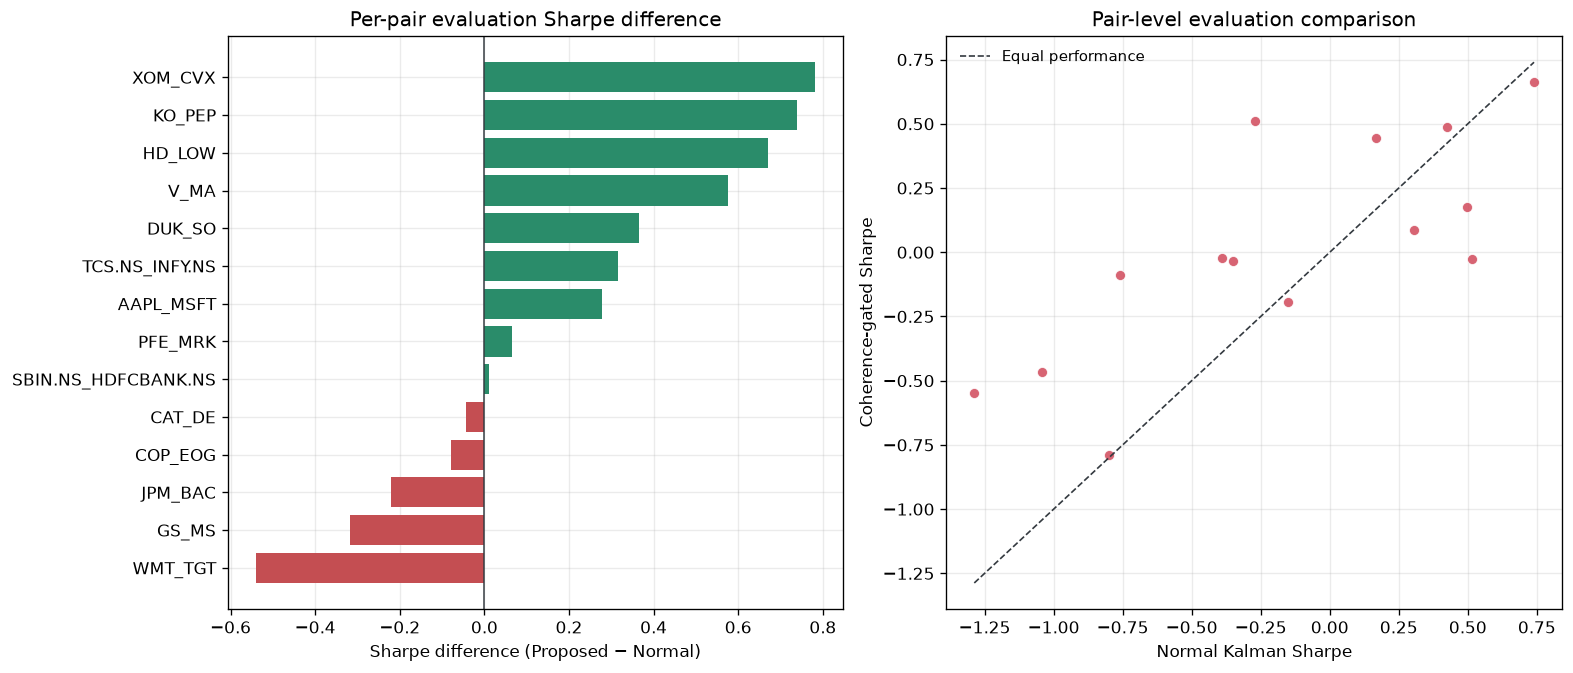

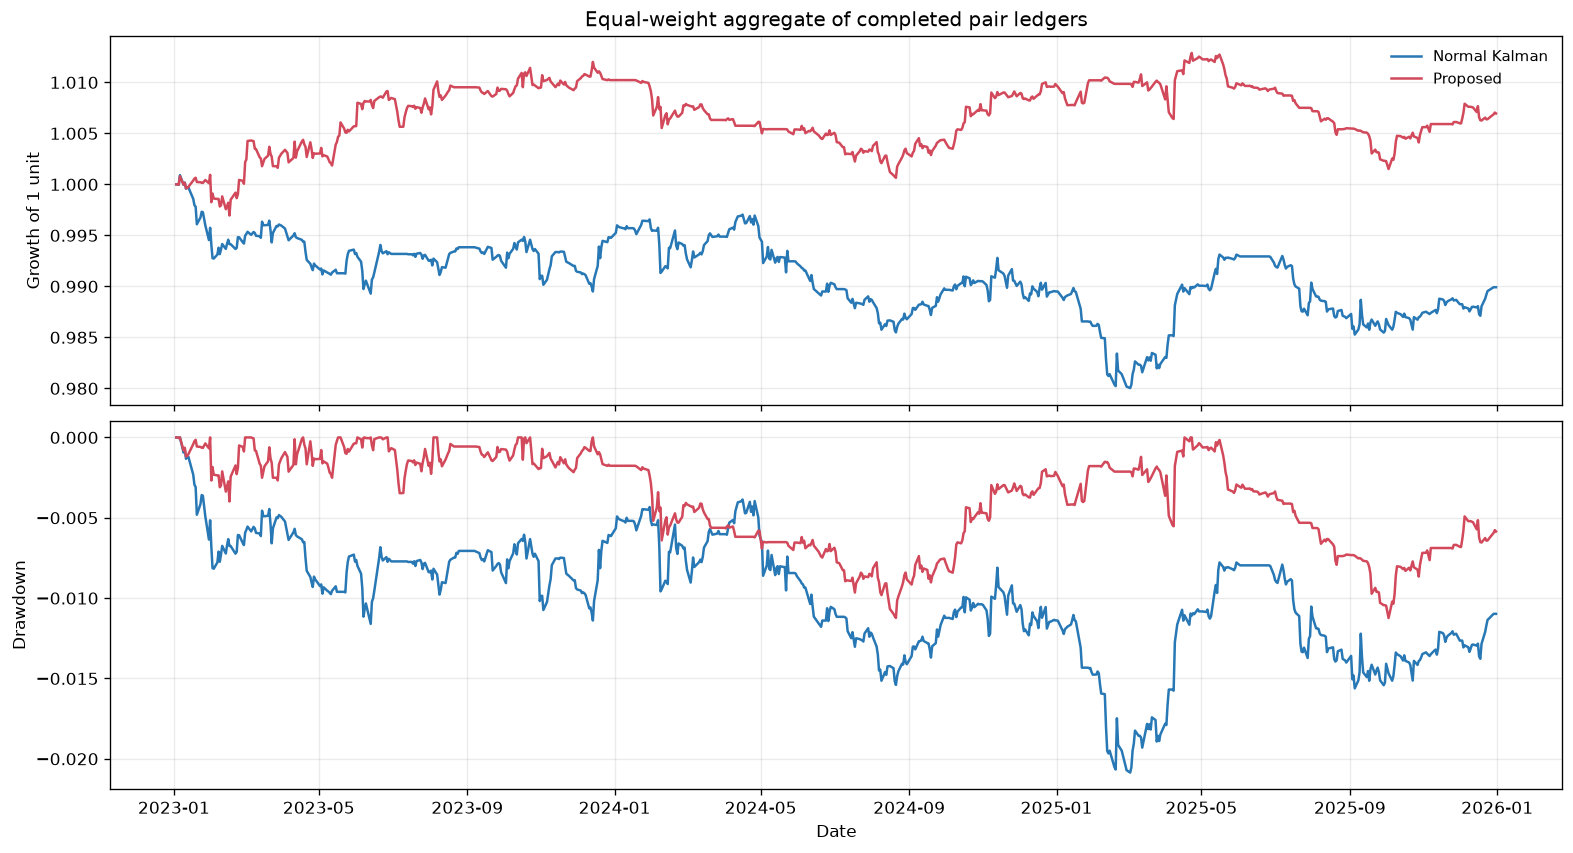

Combined outputs: E:\Academics_in_IITB\Wavelet coherence\Final\final_multiple_pair_outputs


In [10]:

# Reporting only: all pair-level selections were completed in the preceding cells.
def summarize_series(s):
    s=s.dropna(); r=s.to_numpy(float); eq=np.cumprod(1+r)
    years=max((s.index[-1]-s.index[0]).days/365.25,1/252)
    sd=np.std(r,ddof=1); peak=np.maximum.accumulate(np.r_[1.,eq])[1:]
    return dict(CAGR=eq[-1]**(1/years)-1 if eq[-1]>0 else np.nan,
                total_return=eq[-1]-1,
                Sharpe=np.sqrt(252)*np.mean(r)/sd if sd>1e-12 else np.nan,
                max_drawdown=float(np.min(eq/peak-1)),days=len(s))

def wilson_interval(wins,n,z=1.959963984540054):
    if n==0:return (np.nan,np.nan)
    p=wins/n; den=1+z*z/n; center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return center-half,center+half

PAIR_COMPARISON=pd.DataFrame(); METHOD_SUMMARY=pd.DataFrame()
if len(SUMMARY):
    metrics=['Sharpe','CAGR','max_drawdown','trades','win_rate','invested_fraction','turnover','total_cost']
    wide=SUMMARY.pivot(index='pair',columns='method',values=metrics)
    rows=[]
    for pair in wide.index:
        try:
            row={'pair':pair}
            for metric in metrics:
                row['normal_'+metric]=wide.loc[pair,(metric,'Normal Kalman')]
                row['proposed_'+metric]=wide.loc[pair,(metric,'Proposed')]
            row['delta_Sharpe']=row['proposed_Sharpe']-row['normal_Sharpe']
            row['delta_CAGR']=row['proposed_CAGR']-row['normal_CAGR']
            rows.append(row)
        except KeyError: pass
    PAIR_COMPARISON=pd.DataFrame(rows)
    METHOD_SUMMARY=(SUMMARY.groupby('method').agg(
        completed_pairs=('pair','nunique'),median_Sharpe=('Sharpe','median'),mean_Sharpe=('Sharpe','mean'),
        median_CAGR=('CAGR','median'),mean_CAGR=('CAGR','mean'),
        median_max_drawdown=('max_drawdown','median'),median_trades=('trades','median'),
        median_invested_fraction=('invested_fraction','median'),median_turnover=('turnover','median'))
        .reset_index())

# Equal capital to every pair that produced both locked evaluation runs. Dates use their intersection.
normal_cols=[]; proposed_cols=[]
for key,result in RESULTS.items():
    if {'Normal Kalman','Proposed'} <= set(result['runs']):
        normal_cols.append(result['runs']['Normal Kalman']['daily'].set_index('Date').net_return.rename(key))
        proposed_cols.append(result['runs']['Proposed']['daily'].set_index('Date').net_return.rename(key))
PORTFOLIO_DAILY=pd.DataFrame(); PORTFOLIO_METRICS=pd.DataFrame(); PORTFOLIO_INTERVALS=pd.DataFrame()
if normal_cols and proposed_cols:
    normal=pd.concat(normal_cols,axis=1,join='inner').mean(axis=1)
    proposed=pd.concat(proposed_cols,axis=1,join='inner').mean(axis=1)
    idx=normal.index.intersection(proposed.index); normal=normal.loc[idx]; proposed=proposed.loc[idx]
    PORTFOLIO_DAILY=pd.DataFrame({'Normal Kalman':normal,'Proposed':proposed})
    PORTFOLIO_METRICS=pd.DataFrame([dict(method='Normal Kalman',**summarize_series(normal)),
                                    dict(method='Proposed',**summarize_series(proposed))])
    PORTFOLIO_INTERVALS=paired_block_intervals(normal.to_numpy(),proposed.to_numpy(),CONFIG)

COMBINED_TEST=pd.DataFrame()
if len(PAIR_COMPARISON):
    ds=PAIR_COMPARISON.delta_Sharpe.dropna().to_numpy(float); n=len(ds); wins=int((ds>0).sum())
    lo,hi=wilson_interval(wins,n); rng=np.random.default_rng(CONFIG['SEED']+91)
    med_boot=np.array([np.median(rng.choice(ds,size=n,replace=True)) for _ in range(CONFIG['PAIR_BOOTSTRAP_REPS'])]) if n else np.array([])
    q=np.quantile(med_boot,[.025,.975]) if len(med_boot) else [np.nan,np.nan]
    COMBINED_TEST=pd.DataFrame([
        dict(metric='Completed paired evaluations',estimate=n,lower_95=np.nan,upper_95=np.nan),
        dict(metric='Fraction proposed Sharpe wins',estimate=wins/n if n else np.nan,lower_95=lo,upper_95=hi),
        dict(metric='Median pair Sharpe difference',estimate=np.median(ds) if n else np.nan,lower_95=q[0],upper_95=q[1]),
        dict(metric='Normal candidate count',estimate=len(CONFIG['STOP_GRID']),lower_95=np.nan,upper_95=np.nan),
        dict(metric='Proposed candidate count',estimate=len(CONFIG['STOP_GRID'])*len(CONFIG['LOOKBACK_GRID']),lower_95=np.nan,upper_95=np.nan),
    ])

print('\nPAIR-BY-PAIR EVALUATION-PERIOD COMPARISON'); display(PAIR_COMPARISON.round(4).fillna('N/A'))
print('\nCROSS-PAIR METHOD SUMMARY'); display(METHOD_SUMMARY.round(4).fillna('N/A'))
print('\nEQUAL-WEIGHT PORTFOLIO'); display(PORTFOLIO_METRICS.round(4).fillna('N/A'))
print('\nPORTFOLIO PAIRED BLOCK-BOOTSTRAP: PROPOSED MINUS NORMAL'); display(PORTFOLIO_INTERVALS.round(4).fillna('N/A'))
print('\nCROSS-PAIR EVIDENCE AND SEARCH-BUDGET DISCLOSURE'); display(COMBINED_TEST.round(4).fillna('N/A'))

PAIR_COMPARISON.to_csv(OUT/'paired_pair_comparison.csv',index=False)
METHOD_SUMMARY.to_csv(OUT/'cross_pair_method_summary.csv',index=False)
PORTFOLIO_DAILY.to_csv(OUT/'equal_weight_portfolio_daily.csv')
PORTFOLIO_METRICS.to_csv(OUT/'equal_weight_portfolio_metrics.csv',index=False)
PORTFOLIO_INTERVALS.to_csv(OUT/'equal_weight_portfolio_intervals.csv',index=False)
COMBINED_TEST.to_csv(OUT/'combined_evidence_summary.csv',index=False)

if len(PAIR_COMPARISON):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
    order = PAIR_COMPARISON.sort_values('delta_Sharpe')
    axes[0].barh(order.pair, order.delta_Sharpe,
                 color=np.where(order.delta_Sharpe >= 0, GAIN_COLOR, LOSS_COLOR))
    axes[0].axvline(0, color='#343A40', linewidth=0.9)
    axes[0].set(xlabel='Sharpe difference (Proposed − Normal)', title='Per-pair evaluation Sharpe difference')
    axes[1].scatter(PAIR_COMPARISON.normal_Sharpe, PAIR_COMPARISON.proposed_Sharpe,
                    color=METHOD_COLORS['Proposed'], alpha=0.85, edgecolor='white', linewidth=0.5)
    vals = PAIR_COMPARISON[['normal_Sharpe', 'proposed_Sharpe']].to_numpy(float)
    lo2, hi2 = np.nanmin(vals), np.nanmax(vals)
    axes[1].plot([lo2, hi2], [lo2, hi2], linestyle='--', color='#343A40', linewidth=1.0, label='Equal performance')
    axes[1].set(xlabel='Normal Kalman Sharpe', ylabel='Coherence-gated Sharpe',
                title='Pair-level evaluation comparison')
    axes[1].legend(loc='best')
    fig.savefig(OUT / 'cross_pair_sharpe_comparison.png', bbox_inches='tight')
    plt.show()
if len(PORTFOLIO_DAILY):
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, constrained_layout=True)
    for method in ['Normal Kalman', 'Proposed']:
        equity = (1 + PORTFOLIO_DAILY[method]).cumprod()
        peak = np.maximum.accumulate(np.r_[1.0, equity])[1:]
        axes[0].plot(PORTFOLIO_DAILY.index, equity, label=method, color=METHOD_COLORS[method])
        axes[1].plot(PORTFOLIO_DAILY.index, equity / peak - 1, label=method, color=METHOD_COLORS[method])
    axes[0].set(title='Equal-weight aggregate of completed pair ledgers', ylabel='Growth of 1 unit')
    axes[0].legend()
    axes[1].set(ylabel='Drawdown', xlabel='Date')
    fig.savefig(OUT / 'equal_weight_aggregate_performance.png', bbox_inches='tight')
    plt.show()
print('Combined outputs:',OUT.resolve())


Association between the selected development score and evaluation metrics


,scope,n,pearson,pearson_p,spearman,spearman_p,slope
0,Normal Kalman: development Sharpe → evaluation...,14,0.226,0.437,0.319,0.267,0.471
1,Normal Kalman: development Sharpe → evaluation...,14,0.203,0.487,0.319,0.267,0.013
2,Proposed: development Sharpe → evaluation Sharpe,14,0.038,0.896,-0.020,0.946,0.048
3,Proposed: development Sharpe → evaluation CAGR,14,0.026,0.931,0.033,0.911,0.001
4,Pooled (both methods): development Sharpe → ev...,28,0.223,0.254,0.194,0.322,0.246
5,Pooled (both methods): development Sharpe → ev...,28,0.161,0.413,0.161,0.412,0.006
6,Paired differences: development Sharpe → evalu...,14,-0.152,0.603,-0.152,0.605,-0.158


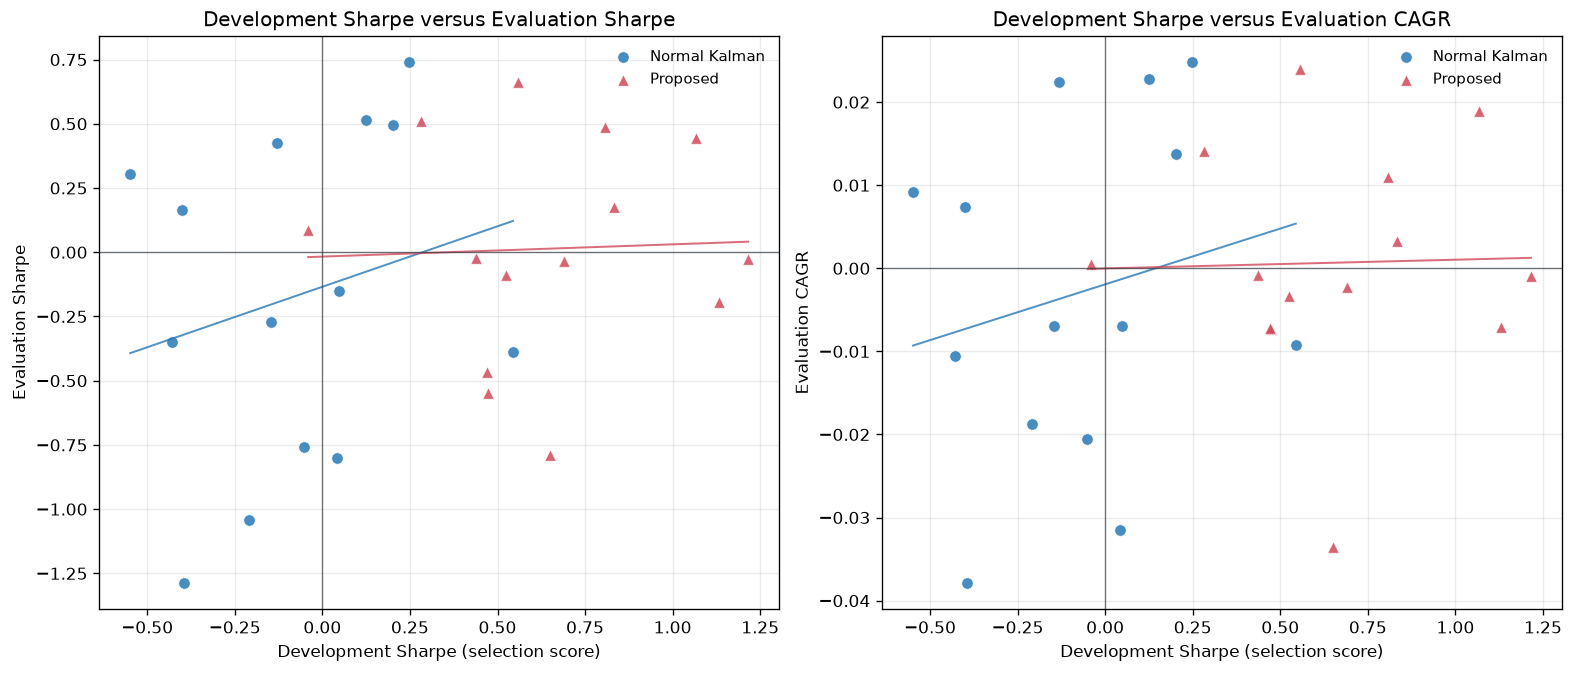

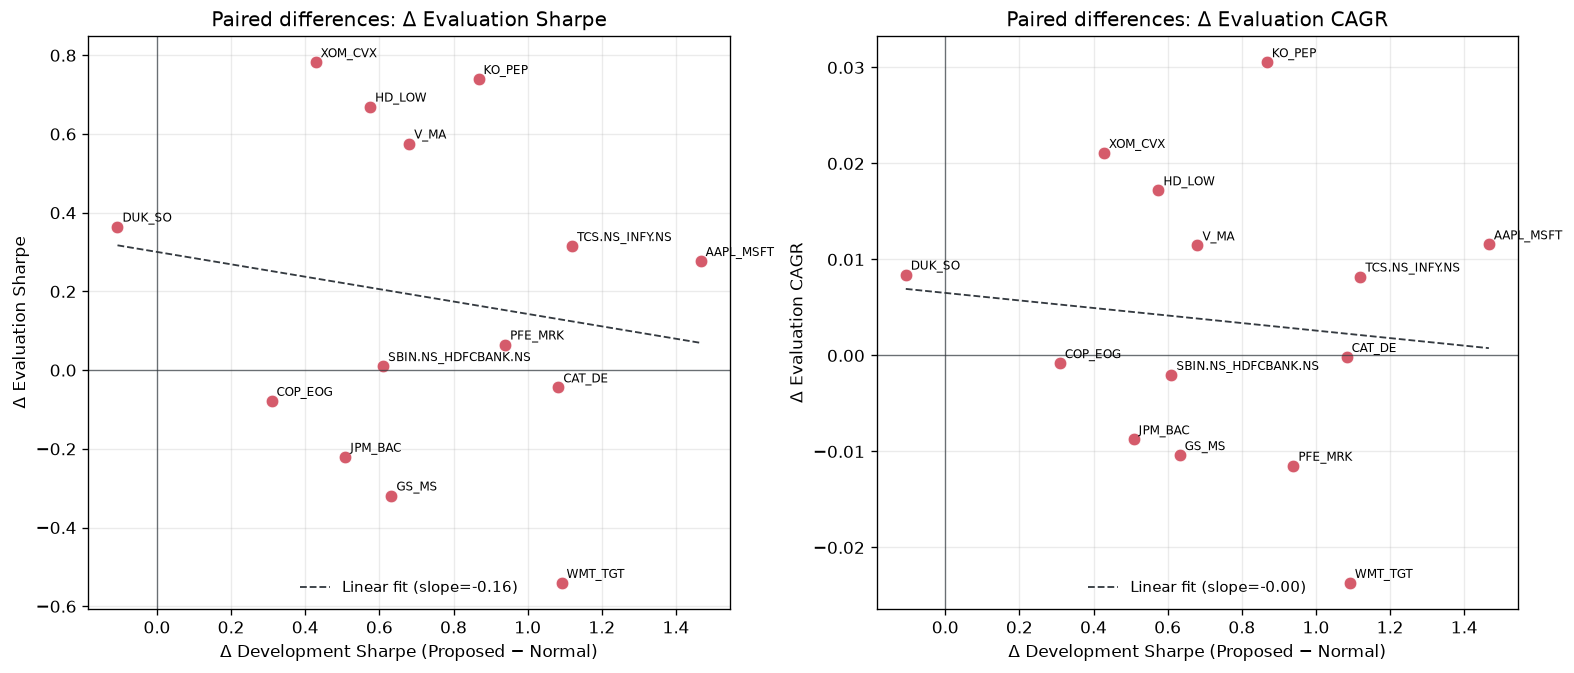

In [11]:
# ---- Development score versus evaluation performance ----
from scipy import stats

# SUMMARY contains the selected configuration's development score and evaluation metrics.
df = SUMMARY.dropna(subset=['training_score', 'Sharpe', 'CAGR']).copy()
df['delta_train'] = np.nan
df['delta_evaluation_Sharpe'] = np.nan
df['delta_evaluation_CAGR'] = np.nan

# Paired differences compare both methods on the same pair.
for pair, group in df.groupby('pair'):
    if {'Normal Kalman', 'Proposed'} <= set(group.method):
        normal = group[group.method == 'Normal Kalman'].iloc[0]
        proposed = group[group.method == 'Proposed'].iloc[0]
        proposed_row = df.index[(df.pair == pair) & (df.method == 'Proposed')]
        df.loc[proposed_row, 'delta_train'] = proposed.training_score - normal.training_score
        df.loc[proposed_row, 'delta_evaluation_Sharpe'] = proposed.Sharpe - normal.Sharpe
        df.loc[proposed_row, 'delta_evaluation_CAGR'] = proposed.CAGR - normal.CAGR


def correlation_summary(sample, x_column, y_column, label):
    """Report Pearson/Spearman associations and an OLS slope when enough pairs exist."""
    x = sample[x_column].to_numpy(float)
    y = sample[y_column].to_numpy(float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    if len(x) < 3:
        return dict(scope=label, n=len(x), pearson=np.nan, pearson_p=np.nan,
                    spearman=np.nan, spearman_p=np.nan, slope=np.nan)
    pearson, pearson_p = stats.pearsonr(x, y)
    spearman, spearman_p = stats.spearmanr(x, y)
    slope = np.polyfit(x, y, 1)[0]
    return dict(scope=label, n=len(x), pearson=pearson, pearson_p=pearson_p,
                spearman=spearman, spearman_p=spearman_p, slope=slope)


rows = []
for method_name in ['Normal Kalman', 'Proposed', 'Pooled (both methods)']:
    subset = df if method_name.startswith('Pooled') else df[df.method == method_name]
    rows.append(correlation_summary(subset, 'training_score', 'Sharpe',
                                    f'{method_name}: development Sharpe → evaluation Sharpe'))
    rows.append(correlation_summary(subset, 'training_score', 'CAGR',
                                    f'{method_name}: development Sharpe → evaluation CAGR'))
rows.append(correlation_summary(
    df[df.method == 'Proposed'], 'delta_train', 'delta_evaluation_Sharpe',
    'Paired differences: development Sharpe → evaluation Sharpe'))
CORRELATIONS = pd.DataFrame(rows)
print('Association between the selected development score and evaluation metrics')
display(CORRELATIONS.round(3))

# Development Sharpe versus evaluation outcomes.
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
for ax, metric, metric_label in [
    (axes[0], 'Sharpe', 'Evaluation Sharpe'),
    (axes[1], 'CAGR', 'Evaluation CAGR'),
]:
    for method_name, subset in df.groupby('method'):
        color = METHOD_COLORS.get(method_name, '#6C757D')
        ax.scatter(subset.training_score, subset[metric], s=48, color=color,
                   marker={'Normal Kalman': 'o', 'Proposed': '^'}.get(method_name, 'o'),
                   alpha=0.85, edgecolor='white', linewidth=0.5, label=method_name)
        x = subset.training_score.to_numpy(float)
        y = subset[metric].to_numpy(float)
        valid = np.isfinite(x) & np.isfinite(y)
        if valid.sum() >= 3:
            slope, intercept = np.polyfit(x[valid], y[valid], 1)
            grid_x = np.linspace(x[valid].min(), x[valid].max(), 50)
            ax.plot(grid_x, intercept + slope * grid_x, color=color, linewidth=1.2, alpha=0.8)
    ax.axhline(0, color='#343A40', linewidth=0.8, alpha=0.7)
    ax.axvline(0, color='#343A40', linewidth=0.8, alpha=0.7)
    ax.set(xlabel='Development Sharpe (selection score)', ylabel=metric_label,
           title=f'Development Sharpe versus {metric_label}')
    ax.legend(loc='best')
fig.savefig(OUT / 'development_score_vs_evaluation.png', bbox_inches='tight')
plt.show()

# Paired differences: does a relative development improvement align with evaluation improvement?
paired = df[df.method == 'Proposed'].dropna(
    subset=['delta_train', 'delta_evaluation_Sharpe', 'delta_evaluation_CAGR'])
if not paired.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
    for ax, metric, metric_label in [
        (axes[0], 'delta_evaluation_Sharpe', 'Δ Evaluation Sharpe'),
        (axes[1], 'delta_evaluation_CAGR', 'Δ Evaluation CAGR'),
    ]:
        ax.scatter(paired.delta_train, paired[metric], s=58, color=METHOD_COLORS['Proposed'],
                   edgecolor='white', linewidth=0.5, alpha=0.9)
        for _, row in paired.iterrows():
            ax.annotate(row['pair'], (row.delta_train, row[metric]), fontsize=7,
                        xytext=(3, 3), textcoords='offset points')
        x = paired.delta_train.to_numpy(float)
        y = paired[metric].to_numpy(float)
        valid = np.isfinite(x) & np.isfinite(y)
        if valid.sum() >= 3:
            slope, intercept = np.polyfit(x[valid], y[valid], 1)
            grid_x = np.linspace(x[valid].min(), x[valid].max(), 50)
            ax.plot(grid_x, intercept + slope * grid_x, color='#343A40', linewidth=1.1,
                    linestyle='--', label=f'Linear fit (slope={slope:.2f})')
            ax.legend(loc='best')
        ax.axhline(0, color='#343A40', linewidth=0.8, alpha=0.7)
        ax.axvline(0, color='#343A40', linewidth=0.8, alpha=0.7)
        ax.set(xlabel='Δ Development Sharpe (Proposed − Normal)', ylabel=metric_label,
               title=f'Paired differences: {metric_label}')
    fig.savefig(OUT / 'paired_development_score_differences.png', bbox_inches='tight')
    plt.show()
else:
    print('Not enough paired results to plot development-score differences.')


Selected configurations with both development and evaluation metrics: 28


,pair,method,lookback,stop,development_Sharpe,development_CAGR,development_trades,evaluation_CAGR,evaluation_Sharpe,evaluation_trades
16,AAPL_MSFT,Normal Kalman,0,4.4,-0.3995,-0.0219,16,0.0074,0.1656,15
20,CAT_DE,Normal Kalman,0,3.8,0.0484,0.0011,19,-0.0070,-0.1511,13
0,COP_EOG,Normal Kalman,0,4.0,0.2481,0.0150,16,0.0248,0.7396,14
22,DUK_SO,Normal Kalman,0,4.6,0.5441,0.0234,12,-0.0092,-0.3887,13
4,GS_MS,Normal Kalman,0,3.8,0.2015,0.0059,14,0.0137,0.4958,13
10,HD_LOW,Normal Kalman,0,4.0,-0.0513,-0.0034,16,-0.0205,-0.7580,14
2,JPM_BAC,Normal Kalman,0,4.6,-0.5486,-0.0225,12,0.0092,0.3049,14
6,KO_PEP,Normal Kalman,0,3.8,-0.3951,-0.0127,23,-0.0379,-1.2874,20
24,PFE_MRK,Normal Kalman,0,4.6,-0.1309,-0.0169,18,0.0224,0.4242,14
18,SBIN.NS_HDFCBANK.NS,Normal Kalman,0,4.0,0.0413,0.0001,15,-0.0315,-0.8005,10


Association between development CAGR and evaluation CAGR


,scope,n,pearson,pearson_p,spearman,spearman_p,slope,intercept
0,Normal Kalman: development CAGR → evaluation CAGR,14,0.1172,0.6898,0.2308,0.4273,0.1632,-0.0022
1,Proposed: development CAGR → evaluation CAGR,14,-0.1884,0.5190,-0.0505,0.8637,-0.1025,0.0045
2,Pooled: development CAGR → evaluation CAGR,28,0.0468,0.8129,0.1303,0.5088,0.0270,-0.0016


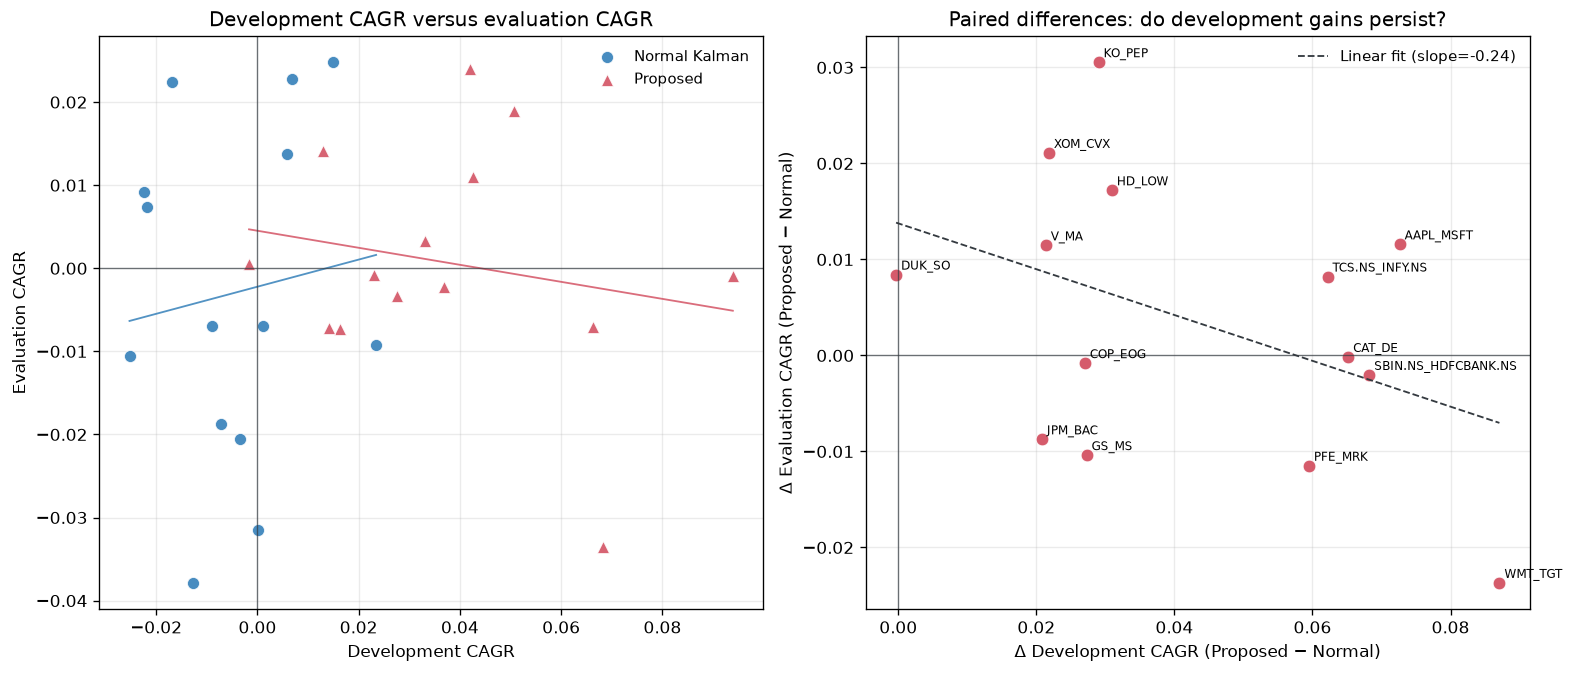

Top 3 configurations per method by development CAGR (with evaluation CAGR shown):

Normal Kalman
   pair  development_CAGR  evaluation_CAGR
 DUK_SO            0.0234          -0.0092
COP_EOG            0.0150           0.0248
WMT_TGT            0.0068           0.0228

Proposed
               pair  development_CAGR  evaluation_CAGR
            WMT_TGT            0.0939          -0.0009
SBIN.NS_HDFCBANK.NS            0.0683          -0.0335
             CAT_DE            0.0662          -0.0071


In [12]:
# ---- Development CAGR versus evaluation CAGR ----
from scipy import stats

# Keep the actual selected model parameters and their development metrics for each pair.
records = []
for pair_name, result in RESULTS.items():
    for method_name, winner in result['winners'].items():
        records.append(dict(
            pair=pair_name,
            method=method_name,
            lookback=int(winner['lookback']),
            stop=float(winner['stop']),
            development_Sharpe=float(winner['training_Sharpe']),
            development_CAGR=float(winner['training_CAGR']),
            development_trades=int(winner['total_trades']),
        ))
DEVELOPMENT = pd.DataFrame(records)
EVALUATION = SUMMARY[['pair', 'method', 'CAGR', 'Sharpe', 'trades']].rename(
    columns={'CAGR': 'evaluation_CAGR', 'Sharpe': 'evaluation_Sharpe', 'trades': 'evaluation_trades'}
)
COMPARISON = DEVELOPMENT.merge(EVALUATION, on=['pair', 'method'], how='inner')
COMPARISON = COMPARISON.dropna(subset=['development_CAGR', 'evaluation_CAGR'])

print('Selected configurations with both development and evaluation metrics:', len(COMPARISON))
display(COMPARISON.sort_values(['method', 'pair']).round(4))


def cagr_correlation_summary(sample, x_column, y_column, label):
    x = sample[x_column].to_numpy(float)
    y = sample[y_column].to_numpy(float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    if len(x) < 3:
        return dict(scope=label, n=len(x), pearson=np.nan, pearson_p=np.nan,
                    spearman=np.nan, spearman_p=np.nan, slope=np.nan, intercept=np.nan)
    pearson, pearson_p = stats.pearsonr(x, y)
    spearman, spearman_p = stats.spearmanr(x, y)
    slope, intercept = np.polyfit(x, y, 1)
    return dict(scope=label, n=len(x), pearson=pearson, pearson_p=pearson_p,
                spearman=spearman, spearman_p=spearman_p, slope=slope, intercept=intercept)


correlations = []
for method_name in ['Normal Kalman', 'Proposed', 'Pooled']:
    subset = COMPARISON if method_name == 'Pooled' else COMPARISON[COMPARISON.method == method_name]
    correlations.append(cagr_correlation_summary(
        subset, 'development_CAGR', 'evaluation_CAGR',
        f'{method_name}: development CAGR → evaluation CAGR'))
print('Association between development CAGR and evaluation CAGR')
display(pd.DataFrame(correlations).round(4))

# Compare development/evaluation CAGR and the paired difference between methods.
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
for method_name, subset in COMPARISON.groupby('method'):
    color = METHOD_COLORS[method_name]
    axes[0].scatter(subset.development_CAGR, subset.evaluation_CAGR, s=52,
                    color=color, marker={'Normal Kalman': 'o', 'Proposed': '^'}[method_name],
                    alpha=0.85, edgecolor='white', linewidth=0.5, label=method_name)
    x = subset.development_CAGR.to_numpy(float)
    y = subset.evaluation_CAGR.to_numpy(float)
    valid = np.isfinite(x) & np.isfinite(y)
    if valid.sum() >= 3:
        slope, intercept = np.polyfit(x[valid], y[valid], 1)
        grid_x = np.linspace(x[valid].min(), x[valid].max(), 50)
        axes[0].plot(grid_x, intercept + slope * grid_x, color=color, linewidth=1.1, alpha=0.8)
axes[0].axhline(0, color='#343A40', linewidth=0.8, alpha=0.7)
axes[0].axvline(0, color='#343A40', linewidth=0.8, alpha=0.7)
axes[0].set(xlabel='Development CAGR', ylabel='Evaluation CAGR',
            title='Development CAGR versus evaluation CAGR')
axes[0].legend(loc='best')

paired = COMPARISON.pivot(index='pair', columns='method', values=['development_CAGR', 'evaluation_CAGR'])
required_columns = [('development_CAGR', 'Proposed'), ('development_CAGR', 'Normal Kalman'),
                    ('evaluation_CAGR', 'Proposed'), ('evaluation_CAGR', 'Normal Kalman')]
if all(column in paired.columns for column in required_columns):
    paired = paired.dropna(subset=required_columns)
    delta_development = paired[('development_CAGR', 'Proposed')] - paired[('development_CAGR', 'Normal Kalman')]
    delta_evaluation = paired[('evaluation_CAGR', 'Proposed')] - paired[('evaluation_CAGR', 'Normal Kalman')]
    axes[1].scatter(delta_development, delta_evaluation, s=58,
                    color=METHOD_COLORS['Proposed'], edgecolor='white', linewidth=0.5, alpha=0.9)
    for pair_name in delta_development.index:
        axes[1].annotate(pair_name, (delta_development[pair_name], delta_evaluation[pair_name]),
                         fontsize=7, xytext=(3, 3), textcoords='offset points')
    if len(delta_development) >= 3:
        slope, intercept = np.polyfit(delta_development.to_numpy(float), delta_evaluation.to_numpy(float), 1)
        grid_x = np.linspace(delta_development.min(), delta_development.max(), 50)
        axes[1].plot(grid_x, intercept + slope * grid_x, color='#343A40', linestyle='--',
                     linewidth=1.1, label=f'Linear fit (slope={slope:.2f})')
        axes[1].legend(loc='best')
    axes[1].set(xlabel='Δ Development CAGR (Proposed − Normal)',
                ylabel='Δ Evaluation CAGR (Proposed − Normal)',
                title='Paired differences: do development gains persist?')
else:
    axes[1].text(0.5, 0.5, 'No complete paired comparisons', ha='center', va='center', transform=axes[1].transAxes)
    axes[1].set_axis_off()
axes[1].axhline(0, color='#343A40', linewidth=0.8, alpha=0.7)
axes[1].axvline(0, color='#343A40', linewidth=0.8, alpha=0.7)
fig.savefig(OUT / 'development_cagr_vs_evaluation_cagr.png', bbox_inches='tight')
plt.show()

print('Top 3 configurations per method by development CAGR (with evaluation CAGR shown):')
for method_name, subset in COMPARISON.groupby('method'):
    top = subset.sort_values('development_CAGR', ascending=False).head(3)
    print(f'\n{method_name}')
    print(top[['pair', 'development_CAGR', 'evaluation_CAGR']].round(4).to_string(index=False))


## Interpretation and next steps

1. Inspect candidate eligibility and the proposed-method heatmap. A winner on the edge of the stop grid is a sensitivity warning, not a reason to expand the search after reviewing evaluation results.
2. Compare net CAGR, Sharpe, drawdown, exposure, turnover, transaction costs, and trade counts together. Inspect concentration in the largest trades; no universal trade-count threshold establishes statistical significance.
3. Paired block-bootstrap intervals reuse the same sampled dates for both methods. They remain conditional on the chosen settings and do not remove selection bias, cross-pair dependence, or researcher degrees of freedom.
4. Keep the pair universe fixed before running the evaluation. Do not remove pairs because of poor or ineligible results. Pairs can share assets and their returns can be correlated.
5. The 2023–2025 window in this configuration is exploratory, not an untouched evaluation period. For a stronger test, freeze the methodology first and evaluate on a genuinely unused date range or predeclared universe, then consider forward paper trading.
6. A larger stop grid is a different, predeclared risk choice. Change `STOP_Z_MAX` and `STOP_GRID` for both systems before examining new evaluation outcomes; the stop is a spread trigger, not an account-level loss guarantee.
7. The proposed system bundles coherence gating, frozen trade beta/z settings, and other linked rules. Attribute results to the configured system as a whole; use matched-policy ablations to isolate individual mechanisms.

Methodological reference: Bailey et al., [The Probability of Backtest Overfitting](https://www.davidhbailey.com/dhbpapers/backtest-prob.pdf). This notebook does not implement their PBO estimator.
